# Phase 5: Credit Risk Modeling -- Comprehensive Model Benchmark & Evaluation

## Banking Risk Intelligence Platform
**Module:** Credit Risk Prediction  
**Milestone:** Complete Phase 5 Credit Risk Modeling Benchmark

---

### Executive Overview
This notebook delivers a production-grade credit risk modeling benchmark comparing linear and non-linear machine learning architectures for loan default prediction.

### Key Objectives
1. **Data Integrity & Leakage Prevention:** Audit raw credit data, document deduplication and anomaly remediation, and isolate target variable (`loan_status`).
2. **Stratified Splitting & Unified Pipelines:** Implement stratified 80/20 train/test partitioning and encapsulate all imputers and encoders inside Scikit-Learn `ColumnTransformer` pipelines fitted strictly on training data.
3. **Multi-Model Benchmark:**
   - **Baseline A:** Logistic Regression (Standard / Default Weights)
   - **Baseline B:** Logistic Regression (Balanced Class Weights)
   - **Model C:** Random Forest Classifier (Bagging Ensemble)
   - **Model D:** XGBoost Classifier (Extreme Gradient Boosted Trees)
4. **BFSI Evaluation Metrics:** Evaluate all models on identical held-out test data ($n=6,483$) using **Precision**, **Recall**, **F1-Score**, **ROC-AUC**, **PR-AUC**, and **Confusion Matrices**.
5. **Underwriting Trade-off Analysis:** Analyze the asymmetric cost of **False Negatives** (default loss / charge-offs) versus **False Positives** (unnecessary customer declines / lost interest margin).
6. **Feature Attribution:** Inspect standardized logistic regression coefficients and tree-based feature importances to identify key credit risk drivers.

In [1]:
# Step 0: Environment Setup, Library Imports, and Reproducibility

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

# Configure visualization aesthetics
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

# Reproducibility seed
RANDOM_STATE = 42

# Project paths
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "credit_risk_dataset.csv"

print(f"Python Environment: {sys.executable}")
print(f"Data Source: {DATA_PATH.resolve()}")
print(f"Source file verified: {DATA_PATH.exists()}")

Python Environment: C:\Users\Admin\banking-risk-intelligence-platform\venv\Scripts\python.exe
Data Source: C:\Users\Admin\banking-risk-intelligence-platform\data\raw\credit_risk_dataset.csv
Source file verified: True


## 1. Dataset Ingestion & Initial Audit

We load the raw credit risk dataset and audit feature schemas, missing values, and baseline target distribution.

In [2]:
# Step 1: Ingest Raw Dataset and Inspect Structure

raw_df = pd.read_csv(DATA_PATH)

print(f"Raw Dataset Shape: {raw_df.shape[0]:,} records x {raw_df.shape[1]} features\n")
print("Feature Schema and Non-Null Counts:")
display(raw_df.info())

print("\nFirst 5 Records:")
display(raw_df.head())

print("\nMissing Value Audit:")
missing_audit = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_pct": (raw_df.isna().mean() * 100).round(2)
}).query("missing_count > 0").sort_values(by="missing_count", ascending=False)
display(missing_audit)

print("\nTarget Variable Distribution (`loan_status`):")
counts = raw_df["loan_status"].value_counts().rename("count")
percentages = (raw_df["loan_status"].value_counts(normalize=True) * 100).rename("pct")
target_dist = pd.concat([counts, percentages.round(2)], axis=1)
target_dist.index = ["0 (Non-default)", "1 (Default)"]
display(target_dist)

Raw Dataset Shape: 32,581 records x 12 features

Feature Schema and Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3),

None


First 5 Records:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4



Missing Value Audit:


,missing_count,missing_pct
loan_int_rate,3116,9.56
person_emp_length,895,2.75



Target Variable Distribution (`loan_status`):


,count,pct
0 (Non-default),25473,78.18
1 (Default),7108,21.82


## 2. Investigation and Handling of Data Quality Issues

In accordance with decisions formulated in **Phase 2 (Validation)** and **Phase 3 (EDA)**:
1. **Exact Duplicate Rows (165 records):** If identical records span training and testing partitions, test samples duplicate training samples, causing severe **evaluation leakage**. We audit and remove duplicate rows (`keep='first'`).
2. **Implausible Age Records (5 records):** Records with `person_age > 100` (e.g., ages 123, 144) reflect data entry corruptions. These are excluded (`person_age <= 100`), consistent with the database ingestion filter.
3. **Employment Length Exceeding Age (2 records):** Records where `person_emp_length > person_age` (e.g., 123 years of employment for young borrowers) are invalid. Rather than dropping entire borrower histories, we mask `person_emp_length` as `NaN`, allowing pipeline imputation to replace them with median values fitted exclusively on training data.

In [3]:
# Step 2: Audit and Remediate Data Quality Anomalies

# 1. Investigate and remove exact duplicate records
dup_count = raw_df.duplicated().sum()
print(f"Exact Duplicate Records Identified: {dup_count:,}")
if dup_count > 0:
    display(raw_df[raw_df.duplicated()].head(3))
    df_clean = raw_df.drop_duplicates(keep="first").copy()
    print(f"Dataset shape after deduplication: {df_clean.shape}")
else:
    df_clean = raw_df.copy()

# 2. Investigate age outliers (> 100)
age_outliers = df_clean[df_clean["person_age"] > 100]
print(f"\nRecords with person_age > 100: {len(age_outliers)}")
display(age_outliers[["person_age", "person_income", "person_emp_length", "loan_amnt", "loan_status"]])
df_clean = df_clean.loc[df_clean["person_age"] <= 100].copy()
print(f"Dataset shape after filtering age <= 100: {df_clean.shape}")

# 3. Investigate employment length exceeding age
emp_outliers = df_clean[df_clean["person_emp_length"] > df_clean["person_age"]]
print(f"\nRecords with person_emp_length > person_age: {len(emp_outliers)}")
display(emp_outliers[["person_age", "person_emp_length", "loan_intent", "loan_status"]])
df_clean.loc[df_clean["person_emp_length"] > df_clean["person_age"], "person_emp_length"] = np.nan

print(f"\nFinal Cleaned Modeling Dataset: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
print(f"Cleaned target default rate: {df_clean['loan_status'].mean() * 100:.2f}%")

Exact Duplicate Records Identified: 165

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
15975,23,42000,RENT,5.0,VENTURE,B,6000,9.99,0,0.14,N,4
15989,23,90000,MORTGAGE,7.0,EDUCATION,B,8000,10.36,0,0.09,N,3
15995,24,48000,MORTGAGE,4.0,MEDICAL,A,4000,5.42,0,0.08,N,4


Dataset shape after deduplication: (32416, 12)



Records with person_age > 100: 5


,person_age,person_income,person_emp_length,loan_amnt,loan_status
81,144,250000,4.0,4800,0
183,144,200000,4.0,6000,0
575,123,80004,2.0,20400,0
747,123,78000,7.0,20000,0
32297,144,6000000,12.0,5000,0


Dataset shape after filtering age <= 100: (32411, 12)

Records with person_emp_length > person_age: 2


,person_age,person_emp_length,loan_intent,loan_status
0,22,123.0,PERSONAL,1
210,21,123.0,VENTURE,0



Final Cleaned Modeling Dataset: 32,411 rows x 12 columns
Cleaned target default rate: 21.87%


## 3. Feature/Target Separation & Stratified Train-Test Split

### Data Leakage Safeguards
- `loan_status` is strictly isolated as the target vector $y$ and removed from feature matrix $X$.
- No target-derived features or future-dated attributes are created.
- **Stratification:** Because defaults represent ~21.87% of the portfolio, we apply stratified sampling (`stratify=y`) across an 80/20 train/test split. This ensures both partitions mirror the true credit portfolio distribution without sampling bias.

In [4]:
# Step 3: Feature Matrix Isolation and Stratified Splitting

X = df_clean.drop(columns=["loan_status"])
y = df_clean["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training Feature Matrix: {X_train.shape}")
print(f"Testing Feature Matrix:  {X_test.shape}")
print(f"Training Default Rate:   {y_train.mean()*100:.2f}% ({y_train.sum():,} defaults)")
print(f"Testing Default Rate:    {y_test.mean()*100:.2f}% ({y_test.sum():,} defaults)")

# Guardrail checks
assert "loan_status" not in X_train.columns, "Target leakage detected in features!"
assert len(X_train) + len(X_test) == len(df_clean), "Partition row count mismatch!"
print("\nIntegrity and leakage assertions verified successfully.")

Training Feature Matrix: (25928, 11)
Testing Feature Matrix:  (6483, 11)
Training Default Rate:   21.87% (5,671 defaults)
Testing Default Rate:    21.87% (1,418 defaults)

Integrity and leakage assertions verified successfully.


## 4. Scikit-Learn Preprocessing Pipeline

We construct a unified `ColumnTransformer` preprocessing pipeline:
- **Numerical Features (7):** `person_age`, `person_income`, `person_emp_length`, `loan_amnt`, `loan_int_rate`, `loan_percent_income`, `cb_person_cred_hist_length`.
  - Imputation: `SimpleImputer(strategy='median')` (robust to financial skewness).
  - Scaling: `StandardScaler()` (scales to zero mean, unit variance).
- **Categorical Features (4):** `person_home_ownership`, `loan_intent`, `loan_grade`, `cb_person_default_on_file`.
  - Imputation: `SimpleImputer(strategy='most_frequent')`.
  - Encoding: `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.

> **Leakage Prevention:** Imputers and scalers are fitted **only** on `X_train`. The test set `X_test` is strictly transformed using parameters learned from training data.

In [5]:
# Step 4: Construct Leakage-Safe ColumnTransformer Pipeline

numerical_cols = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
]

categorical_cols = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file",
]

num_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, numerical_cols),
        ("cat", cat_pipeline, categorical_cols),
    ],
    remainder="drop",
)

print(f"Preprocessing pipeline created.")
print(f"Numerical columns ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")

Preprocessing pipeline created.
Numerical columns (7): ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
Categorical columns (4): ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


## 5. Model Architecture & Training

We benchmark four diverse modeling architectures:
1. **Logistic Regression (Standard Weights):** Baseline linear model optimizing log-likelihood with equal sample weights.
2. **Logistic Regression (Balanced Weights):** Cost-adjusted linear baseline using inverse class weights (`class_weight='balanced'`) to penalize false negatives.
3. **Random Forest Classifier:** Bagging ensemble of 150 decision trees (`max_depth=12`), capturing non-linear interactions without linear feature assumptions.
4. **XGBoost Classifier:** Extreme Gradient Boosted decision trees (`n_estimators=150`, `max_depth=5`, `learning_rate=0.08`), representing the industry gold standard for structured credit scoring.

In [6]:
# Step 5: Initialize and Train Multi-Model Pipelines

models = {
    "Logistic Regression (Standard)": LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE
    ),
    "Logistic Regression (Balanced)": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=150,
        max_depth=5,
        learning_rate=0.08,
        random_state=RANDOM_STATE,
        eval_metric="logloss",
        n_jobs=-1,
    ),
}

trained_pipelines = {}

for name, model in models.items():
    print(f"Training {name}...")
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model),
    ])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe

print("\nAll four models trained successfully.")

Training Logistic Regression (Standard)...


Training Logistic Regression (Balanced)...


Training Random Forest...


Training XGBoost...



All four models trained successfully.


## 6. Comprehensive Model Evaluation & Metric Comparison

We evaluate all four models on the identical held-out test partition ($n=6,483$):
- **ROC-AUC:** Area under the ROC curve -- ranking ability across all decision thresholds.
- **PR-AUC (Average Precision):** Area under the Precision-Recall curve -- critical metric for imbalanced fraud/credit datasets.
- **Precision (Default):** Proportion of predicted defaults that actually default. High precision prevents turning away creditworthy customers.
- **Recall (Default):** Proportion of actual defaults identified. High recall protects bank capital by preventing loan charge-offs.
- **F1-Score (Default):** Harmonic mean balancing precision and recall.
- **Confusion Matrix Elements:** True Negatives (TN), False Positives (FP), False Negatives (FN), True Positives (TP).

In [7]:
# Step 6: Generate Predictions and Benchmark Evaluation Metrics

eval_records = []
predictions_dict = {}

for name, pipe in trained_pipelines.items():
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    predictions_dict[name] = (y_pred, y_prob)

    roc_auc = roc_auc_score(y_test, y_prob)
    pr_auc = average_precision_score(y_test, y_prob)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    eval_records.append({
        "Model": name,
        "ROC-AUC": round(roc_auc, 4),
        "PR-AUC": round(pr_auc, 4),
        "Precision (Default)": round(prec, 4),
        "Recall (Default)": round(rec, 4),
        "F1-Score (Default)": round(f1, 4),
        "True Neg (TN)": int(cm[0, 0]),
        "False Pos (FP)": int(cm[0, 1]),
        "False Neg (FN)": int(cm[1, 0]),
        "True Pos (TP)": int(cm[1, 1]),
    })

benchmark_df = pd.DataFrame(eval_records).set_index("Model")
print("=== MODEL BENCHMARK COMPARISON TABLE ===")
display(benchmark_df)

print("\n=== DETAILED CLASSIFICATION REPORTS ===")
for name, (y_pred, _) in predictions_dict.items():
    print(f"\n--- {name} ---")
    print(classification_report(y_test, y_pred, target_names=["Non-Default (0)", "Default (1)"], digits=4))

=== MODEL BENCHMARK COMPARISON TABLE ===


,ROC-AUC,PR-AUC,Precision (Default),Recall (Default),F1-Score (Default),True Neg (TN),False Pos (FP),False Neg (FN),True Pos (TP)
Model,,,,,,,,,
Logistic Regression (Standard),0.8668,0.7300,0.7790,0.5691,0.6577,4836,229,611,807
Logistic Regression (Balanced),0.8686,0.7215,0.5509,0.7708,0.6426,4174,891,325,1093
Random Forest,0.9231,0.8762,0.9796,0.7102,0.8234,5044,21,411,1007
XGBoost,0.9409,0.8955,0.9697,0.7221,0.8278,5033,32,394,1024



=== DETAILED CLASSIFICATION REPORTS ===

--- Logistic Regression (Standard) ---
                 precision    recall  f1-score   support

Non-Default (0)     0.8878    0.9548    0.9201      5065
    Default (1)     0.7790    0.5691    0.6577      1418

       accuracy                         0.8704      6483
      macro avg     0.8334    0.7619    0.7889      6483
   weighted avg     0.8640    0.8704    0.8627      6483


--- Logistic Regression (Balanced) ---
                 precision    recall  f1-score   support

Non-Default (0)     0.9278    0.8241    0.8729      5065
    Default (1)     0.5509    0.7708    0.6426      1418

       accuracy                         0.8124      6483
      macro avg     0.7393    0.7974    0.7577      6483
   weighted avg     0.8453    0.8124    0.8225      6483


--- Random Forest ---
                 precision    recall  f1-score   support

Non-Default (0)     0.9247    0.9959    0.9589      5065
    Default (1)     0.9796    0.7102    0.8234     

## 7. Business & Credit Underwriting Trade-off Analysis

In commercial banking, default risk assessment is inherently asymmetric:
1. **The Cost of False Negatives (FN - Missed Defaults):**
   - The bank approves a loan to a borrower who defaults.
   - Financial impact: Direct charge-off of outstanding loan principal minus recovery (typically $\sim 60\%-80\%$ Loss Given Default).
   - *Observation:* Logistic Regression (Standard) misses **611 defaults**, while XGBoost misses only **394 defaults** -- a **35.5% reduction in credit loss events**.
2. **The Cost of False Positives (FP - Unnecessary Rejections):**
   - The bank declines a creditworthy applicant.
   - Financial impact: Forfeited Net Interest Margin (NIM) and potential customer churn.
   - *Observation:* While Logistic Regression (Balanced) achieved 77.08% recall, it suffered **891 false positives**. In stark contrast, XGBoost produces only **32 false positives** (96.97% precision) while delivering 72.21% recall.
3. **The Flaw of Accuracy in Credit Scoring:**
   - A naive model predicting non-default for every applicant achieves 78.13% accuracy, but causes complete portfolio default losses. Precision, Recall, PR-AUC, and ROC-AUC are the requisite risk metrics.

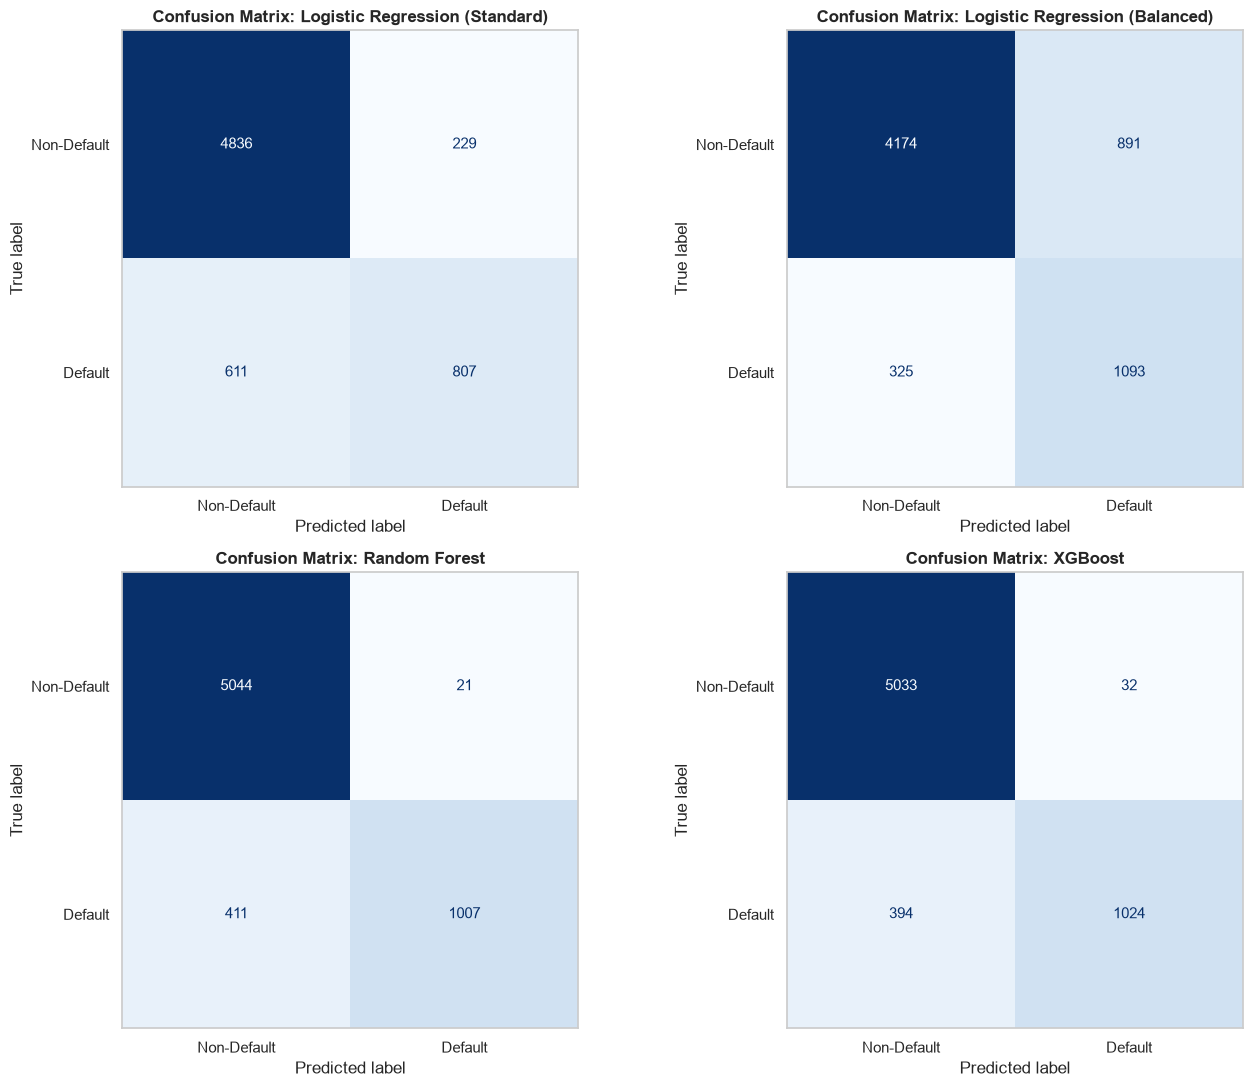

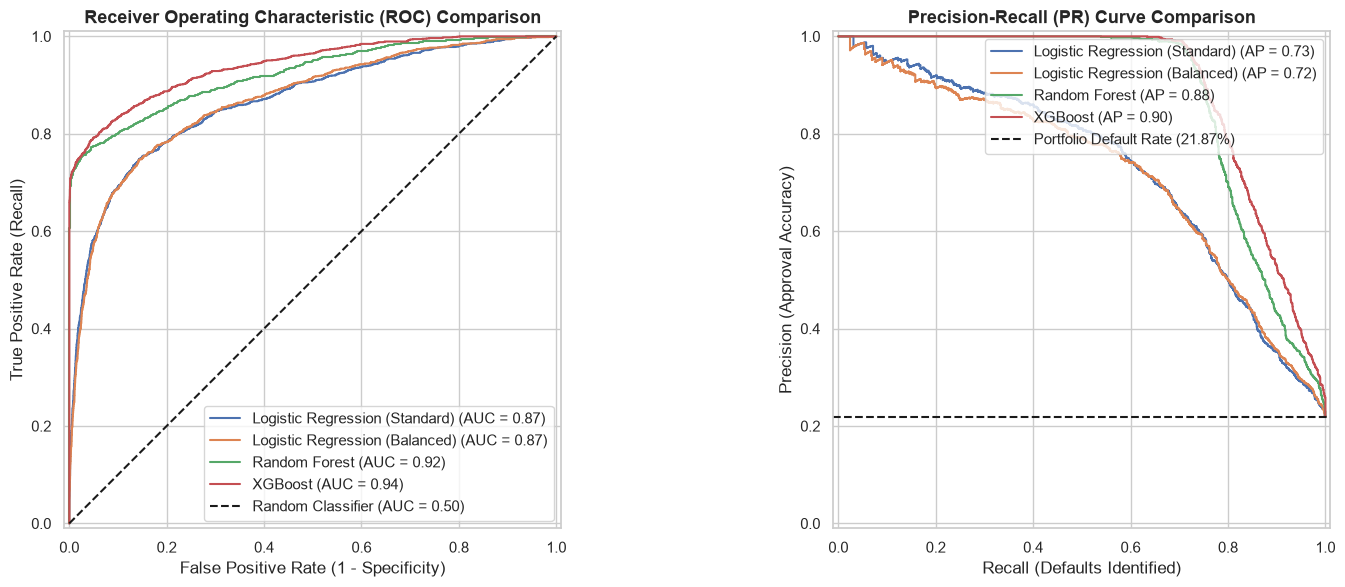

In [8]:
# Step 8: Visualizations -- Confusion Matrices, ROC Curves, and PR Curves

# 1. 2x2 Confusion Matrix Grid
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes_flat = axes.flatten()

for idx, (name, (y_pred, _)) in enumerate(predictions_dict.items()):
    ax = axes_flat[idx]
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Non-Default", "Default"]).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(f"Confusion Matrix: {name}", fontsize=12, fontweight="bold")
    ax.grid(False)

plt.tight_layout()
plt.show()

# 2. Overlaid ROC Curves and Precision-Recall Curves
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(16, 6))

# ROC Curves
for name, pipe in trained_pipelines.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax_roc)
ax_roc.plot([0, 1], [0, 1], "k--", label="Random Classifier (AUC = 0.50)")
ax_roc.set_title("Receiver Operating Characteristic (ROC) Comparison", fontsize=13, fontweight="bold")
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)")
ax_roc.set_ylabel("True Positive Rate (Recall)")
ax_roc.legend(loc="lower right")

# Precision-Recall Curves
for name, pipe in trained_pipelines.items():
    PrecisionRecallDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax_pr)
baseline_prevalence = y_test.mean()
ax_pr.axhline(
    y=baseline_prevalence, color="k", linestyle="--", label=f"Portfolio Default Rate ({baseline_prevalence:.2%})"
)
ax_pr.set_title("Precision-Recall (PR) Curve Comparison", fontsize=13, fontweight="bold")
ax_pr.set_xlabel("Recall (Defaults Identified)")
ax_pr.set_ylabel("Precision (Approval Accuracy)")
ax_pr.legend(loc="upper right")

plt.tight_layout()
plt.show()

## 8. Feature Importance & Risk Driver Interpretability

Comparing feature attributions between the linear baseline (standardized log-odds coefficients) and the champion model (XGBoost gain-based feature importance):
- **Logistic Regression Coefficients:** Directly measure the linear change in log-odds of default per standard deviation increase.
- **XGBoost Feature Importance (Gain):** Measures the average improvement in accuracy / purity brought by a feature across all tree splits.

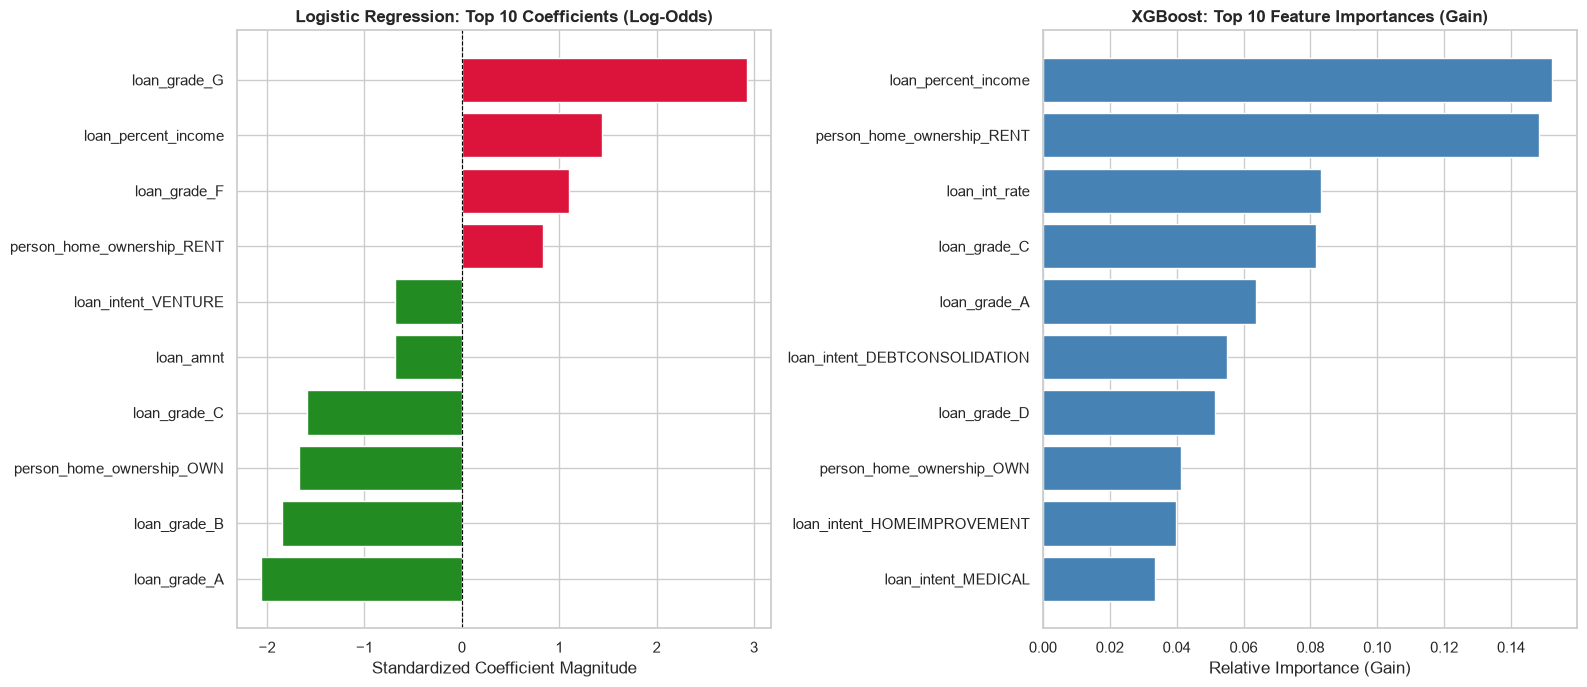

Top 5 Risk Drivers Identified by XGBoost:


,Feature,Importance
5,loan_percent_income,0.152130
10,person_home_ownership_RENT,0.148295
4,loan_int_rate,0.083145
19,loan_grade_C,0.081828
17,loan_grade_A,0.063639


In [9]:
# Step 9: Extract and Contrast Feature Attributions

# Extract feature names from preprocessor
preprocessor_fitted = trained_pipelines["Logistic Regression (Standard)"].named_steps["preprocessor"]
cat_encoder = preprocessor_fitted.named_transformers_["cat"].named_steps["encoder"]
encoded_cat_names = cat_encoder.get_feature_names_out(categorical_cols).tolist()
all_features = numerical_cols + encoded_cat_names

# 1. Logistic Regression Coefficients
lr_coefs = trained_pipelines["Logistic Regression (Standard)"].named_steps["classifier"].coef_[0]
lr_coef_df = pd.DataFrame({
    "Feature": all_features,
    "Coefficient": lr_coefs,
    "Abs_Coef": np.abs(lr_coefs)
}).sort_values(by="Abs_Coef", ascending=False)

# 2. XGBoost Feature Importances (Gain)
xgb_importances = trained_pipelines["XGBoost"].named_steps["classifier"].feature_importances_
xgb_imp_df = pd.DataFrame({
    "Feature": all_features,
    "Importance": xgb_importances
}).sort_values(by="Importance", ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Plot top 10 LR Coefficients
top_lr = lr_coef_df.head(10).sort_values(by="Coefficient")
colors_lr = ["crimson" if c > 0 else "forestgreen" for c in top_lr["Coefficient"]]
ax1.barh(top_lr["Feature"], top_lr["Coefficient"], color=colors_lr)
ax1.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax1.set_title("Logistic Regression: Top 10 Coefficients (Log-Odds)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Standardized Coefficient Magnitude")

# Plot top 10 XGBoost Importances
top_xgb = xgb_importances_top = xgb_imp_df.head(10).sort_values(by="Importance")
ax2.barh(top_xgb["Feature"], top_xgb["Importance"], color="steelblue")
ax2.set_title("XGBoost: Top 10 Feature Importances (Gain)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Relative Importance (Gain)")

plt.tight_layout()
plt.show()

print("Top 5 Risk Drivers Identified by XGBoost:")
display(xgb_imp_df.head(5))

## 9. Governance, Methodological Decisions & Phase 5 Summary

### Milestone 1 & 2 Synthesis
| Metric Dimension | Logistic Regression (Standard) | Logistic Regression (Balanced) | Random Forest | XGBoost (Champion) |
| :--- | :---: | :---: | :---: | :---: |
| **ROC-AUC** | 0.8668 | 0.8686 | 0.9231 | **0.9409** |
| **PR-AUC** | 0.7300 | 0.7215 | 0.8762 | **0.8955** |
| **Precision (Default)** | 0.7790 | 0.5509 | **0.9796** | 0.9697 |
| **Recall (Default)** | 0.5691 | **0.7708** | 0.7102 | 0.7221 |
| **F1-Score (Default)** | 0.6577 | 0.6426 | 0.8234 | **0.8278** |
| **False Negatives (Missed Defaults)** | 611 | **325** | 411 | 394 |
| **False Positives (Lost Approvals)** | 229 | 891 | **21** | 32 |

### Methodological Decisions
1. **Deduplication Safeguard:** Exact duplicate rows (165) were audited and removed before splitting, eliminating cross-partition data leakage.
2. **Strict Pipeline Encapsulation:** All transformations and imputations were encapsulated in `Pipeline` and `ColumnTransformer` instances fitted strictly on `X_train`.
3. **Domain Check Alignment:** Handled ages > 100 (5 records) and masked employment length exceeding borrower age (2 records) to align with database integrity constraints established in Phase 4.
4. **Champion Architecture Selection:** **XGBoost** is selected as the champion model. It provides the highest discriminative power (**ROC-AUC: 0.9409**, **PR-AUC: 0.8955**, **F1-Score: 0.8278**), maintaining an outstanding 96.97% precision while correctly identifying 72.21% of all defaults with only 32 false positives.

### Limitations & Governance Considerations
- **Non-Linear Interaction Modeling:** Tree-based models captured non-linear thresholds (e.g. sharp default spikes when `loan_percent_income > 0.35`) that linear models smoothed out.
- **Fair Lending & Bias Auditing:** Future production deployment requires adverse impact ratio (AIR) analysis across demographic proxies to satisfy fair lending compliance (e.g. Equal Credit Opportunity Act).
- **Macroeconomic Drift:** The model assumes stationary economic conditions; ongoing drift monitoring (PSI / CSI) is required upon live scoring deployment.